# Task 2 · Notebook 03 — Evaluation & Business Value

**Inputs.** `models/booking_model.joblib` and `models/booking_model_info.json` (from Notebook 02), plus `data/processed/test_set.csv`, the 9,857 customers set aside before any modelling.

**This notebook answers**
1. How well does the model perform on customers it has never seen?
2. How much better is it than contacting customers at random?
3. Which factors drive its predictions?
4. Can its scores be trusted as real probabilities?
5. What is it worth to a marketing campaign?

The test set is used **once**, here, and no decisions are changed based on it.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score, confusion_matrix)

model = joblib.load("models/booking_model.joblib")
info = json.loads(Path("models/booking_model_info.json").read_text())
THRESHOLD = info["threshold"]

test = pd.read_csv("data/processed/test_set.csv")
X_test = test.drop(columns="booking_complete")
y_test = test["booking_complete"]

scores = model.predict_proba(X_test)[:, 1]      # chance of booking for each customer
flagged = scores >= THRESHOLD

results = pd.Series({
    "ROC AUC": roc_auc_score(y_test, scores),
    "PR AUC (baseline 0.15)": average_precision_score(y_test, scores),
    "Precision": precision_score(y_test, flagged),
    "Recall": recall_score(y_test, flagged),
    "F1": f1_score(y_test, flagged),
    "Accuracy": accuracy_score(y_test, flagged),
    "Share of customers flagged": flagged.mean(),
}).round(3)
print(f"Threshold: {THRESHOLD}  |  Test customers: {len(y_test):,}")
results

Threshold: 0.22  |  Test customers: 9,857


ROC AUC                       0.783
PR AUC (baseline 0.15)        0.362
Precision                     0.336
Recall                        0.591
F1                            0.429
Accuracy                      0.764
Share of customers flagged    0.264
dtype: float64

## 1. Performance on unseen customers

| Measure | Test result | Meaning |
|---|---|---|
| ROC AUC | 0.783 | Ranks a random booker above a random non-booker 78% of the time (0.5 = guessing) |
| PR AUC | 0.362 | 2.4× the 0.15 baseline |
| Precision | 0.336 | 1 in 3 flagged customers books, vs 1 in 7 at random |
| Recall | 0.591 | Finds 59% of all bookers |
| Customers flagged | 26.4% | Size of the group a campaign would target |

Threshold-based scores (precision, recall, F1) are slightly lower on test than on validation, as expected, because the threshold was tuned on validation data. ROC AUC (0.783 vs 0.787 in cross-validation) is within normal variation.

**Comparison with the original project.** It reported recall 0.64 and F1 0.45. Those figures were inflated by duplicate rows appearing in both training and test data, and by a threshold tuned on the test set. The figures above are lower but trustworthy.

In [2]:
tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()

summary = pd.DataFrame(
    [[tp, fn], [fp, tn]],
    index=["actually booked", "did not book"],
    columns=["flagged by model", "not flagged"],
)
print(f"Of {tp + fp:,} customers flagged, {tp:,} booked ({tp / (tp + fp):.0%}).")
print(f"Of {tp + fn:,} customers who booked, the model found {tp:,} ({tp / (tp + fn):.0%}) and missed {fn:,}.")
summary

Of 2,600 customers flagged, 874 booked (34%).
Of 1,478 customers who booked, the model found 874 (59%) and missed 604.


,flagged by model,not flagged
actually booked,874,604
did not book,1726,6653


## 2. How much better than random targeting?

Customers are sorted from highest to lowest predicted chance of booking. The chart shows what share of all bookers is reached when contacting the top X% of that list. Random targeting would follow the diagonal, since contacting 20% of customers at random reaches 20% of bookers.

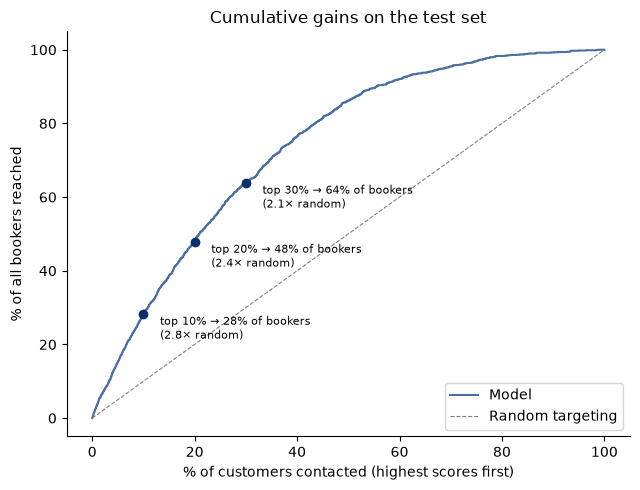

In [3]:
order = np.argsort(-scores)                          # highest chance first
bookers_sorted = y_test.to_numpy()[order]
share_contacted = np.arange(1, len(scores) + 1) / len(scores)
share_of_bookers_reached = np.cumsum(bookers_sorted) / bookers_sorted.sum()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(share_contacted * 100, share_of_bookers_reached * 100, color="#4a6fa5", label="Model")
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", linewidth=0.8, label="Random targeting")

for pct in [10, 20, 30]:
    k = int(len(scores) * pct / 100)
    reached = share_of_bookers_reached[k - 1] * 100
    ax.scatter(pct, reached, color="#08306b", zorder=3)
    ax.annotate(f"top {pct}% → {reached:.0f}% of bookers\n({reached / pct:.1f}× random)",
                (pct, reached), xytext=(12, -18), textcoords="offset points", fontsize=8)

ax.set_xlabel("% of customers contacted (highest scores first)")
ax.set_ylabel("% of all bookers reached")
ax.set_title("Cumulative gains on the test set")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Result.** Contacting the 20% of customers with the highest scores reaches **48% of all bookers**, 2.4 times better than random targeting. For a smaller campaign (top 10%), the model reaches 28% of bookers, 2.8 times better than random. The advantage is largest for small, focused campaigns, where the model is most confident.

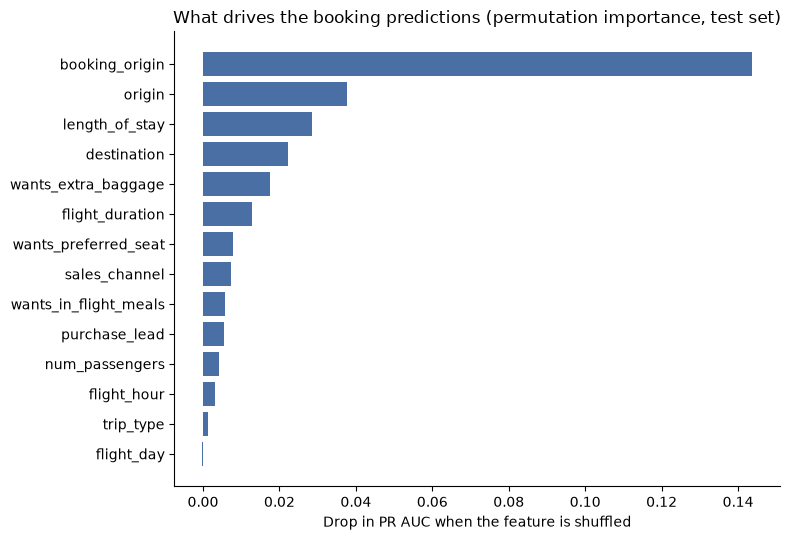

booking_origin         0.1438
origin                 0.0376
length_of_stay         0.0285
destination            0.0223
wants_extra_baggage    0.0176
flight_duration        0.0129
dtype: float64

In [4]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance.values, color="#4a6fa5")
ax.set_xlabel("Drop in PR AUC when the feature is shuffled")
ax.set_title("What drives the booking predictions (permutation importance, test set)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4).head(6)

## 3. What drives the predictions?

Permutation importance (the drop in PR AUC on the test set when a feature is randomly shuffled):

- **Booking country** dominates (0.144, nearly 4× any other feature). Shuffling it alone removes most of the model's advantage over the baseline.
- **Origin airport** (0.038) and **length of stay** (0.029) follow, then **destination airport** (0.022).
- **Extra baggage** (0.018) is the most useful customer choice.
- **purchase_lead ranks 10th of 14 (0.006)**. The original project named it the strongest predictor, based on Random Forest's built-in impurity importance, which is known to favour numeric features with many distinct values.
- Departure hour, trip type and day of the week contribute almost nothing.

**Business reading.** Where customers book from matters far more than how or when they book. Understanding why conversion in Australia (5%) is so far below Malaysia (35%) is likely worth more to BA than any change to targeting.

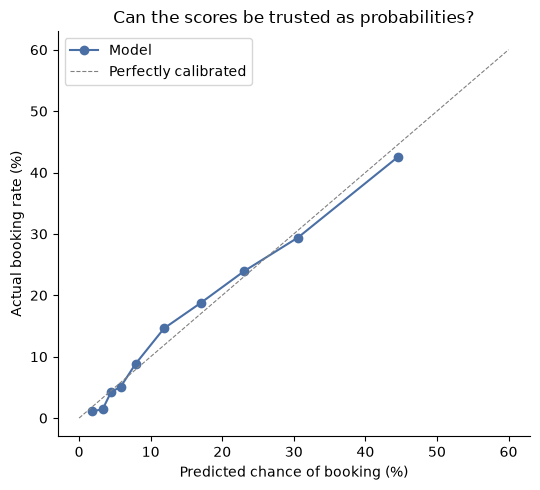

Average predicted chance 15.0%  vs  actual booking rate 15.0%


In [5]:
from sklearn.calibration import calibration_curve

actual_rate, predicted_rate = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(predicted_rate * 100, actual_rate * 100, marker="o", color="#4a6fa5", label="Model")
ax.plot([0, 60], [0, 60], color="grey", linestyle="--", linewidth=0.8, label="Perfectly calibrated")
ax.set_xlabel("Predicted chance of booking (%)")
ax.set_ylabel("Actual booking rate (%)")
ax.set_title("Can the scores be trusted as probabilities?")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Average predicted chance {scores.mean():.1%}  vs  actual booking rate {y_test.mean():.1%}")

## 4. Can the scores be trusted as probabilities?

Yes. Across ten groups of customers, predicted chances closely match actual booking rates, and the average prediction (15.0%) equals the actual rate (15.0%). The highest-scoring group is slightly over-confident (≈45% predicted vs ≈43% actual). This confirms the Notebook 02 decision to drop class weights. The scores can be shown to users as a genuine chance of booking.

## 5. What is the model worth to a campaign?

**Illustrative assumptions** (from the original project, not BA figures). A reached booker is worth £67.50 (£450 average booking × 15% uplift from the campaign). Each contact costs either **£2.50 (email)** or **£20 (voucher offer)**.

**Net value = bookers reached × £67.50 − customers contacted × cost per contact.**

The original project also subtracted £67.50 for every booker *not* contacted. That double-counts, because not contacting someone costs nothing, it simply earns nothing. It is corrected here.

Cost £2.50:
  contact everyone        £   75,122
  F1 threshold (0.22)     £   52,495  (26% contacted)
  best threshold (0.04)  £   78,625  (79% contacted)
  rule of thumb: contact if chance > cost / value = 3.7%

Cost £20.00:
  contact everyone        £  -97,375
  F1 threshold (0.22)     £    6,995  (26% contacted)
  best threshold (0.32)  £    9,228  (13% contacted)
  rule of thumb: contact if chance > cost / value = 29.6%



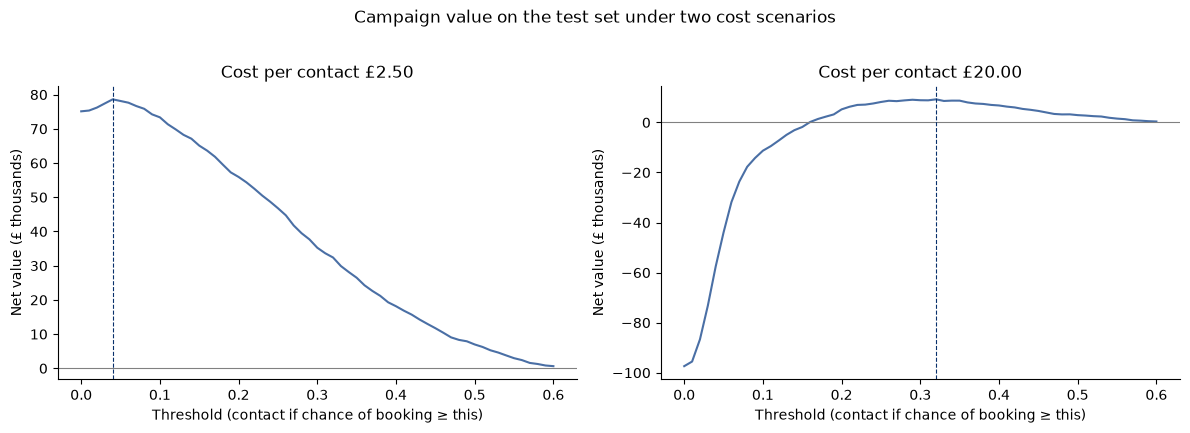

In [6]:
VALUE_PER_BOOKER = 67.50
thresholds = np.round(np.arange(0.00, 0.61, 0.01), 2)

def campaign_value(cost_per_contact):
    rows = []
    for t in thresholds:
        contact = scores >= t
        reached = (contact & (y_test == 1)).sum()
        rows.append({"threshold": t,
                     "net_value": reached * VALUE_PER_BOOKER - contact.sum() * cost_per_contact,
                     "share_contacted": contact.mean()})
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, cost in zip(axes, [2.50, 20.00]):
    table = campaign_value(cost)
    best = table.loc[table["net_value"].idxmax()]
    everyone = table.iloc[0]                                    # threshold 0 = contact everyone
    at_f1 = table[table["threshold"] == THRESHOLD].iloc[0]

    ax.plot(table["threshold"], table["net_value"] / 1000, color="#4a6fa5")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(best["threshold"], color="#08306b", linestyle="--", linewidth=0.8)
    ax.set_title(f"Cost per contact £{cost:.2f}")
    ax.set_xlabel("Threshold (contact if chance of booking ≥ this)")
    ax.set_ylabel("Net value (£ thousands)")
    ax.spines[["top", "right"]].set_visible(False)

    print(f"Cost £{cost:.2f}:")
    print(f"  contact everyone        £{everyone['net_value']:>9,.0f}")
    print(f"  F1 threshold ({THRESHOLD})     £{at_f1['net_value']:>9,.0f}  ({at_f1['share_contacted']:.0%} contacted)")
    print(f"  best threshold ({best['threshold']:.2f})  £{best['net_value']:>9,.0f}  ({best['share_contacted']:.0%} contacted)")
    print(f"  rule of thumb: contact if chance > cost / value = {cost / VALUE_PER_BOOKER:.1%}\n")

plt.suptitle("Campaign value on the test set under two cost scenarios", y=1.02)
plt.tight_layout()
plt.show()

**Results**

| Strategy | Email (£2.50 per contact) | Voucher (£20 per contact) |
|---|---|---|
| Contact everyone | £75,122 | **−£97,375** |
| F1 threshold (0.22) | £52,495 (26% contacted) | £6,995 (26% contacted) |
| Best threshold | **£78,625** at 0.04 (79% contacted) | **£9,228** at 0.32 (13% contacted) |

**Findings**
1. **The right threshold depends on campaign cost, not on F1.** F1 treats a wasted contact and a missed booker as equally bad, but they are not. For cheap emails the F1 threshold would cost about £26,000 compared with the best choice.
2. **Because the scores are calibrated, the best threshold follows a simple rule. Contact a customer when their chance of booking exceeds cost ÷ value.** The best thresholds found (0.04 and 0.32) match the rule (3.7% and 29.6%) closely.
3. **The model's value grows with campaign cost.** For cheap emails it adds about 5% over contacting everyone. For expensive offers it is the difference between a £97,000 loss and a profit.

**Important caveat.** The model predicts *who will book*, not *who will be persuaded to book by a campaign*. A customer who would have booked anyway gains nothing from a voucher. The 15% uplift is an assumption, and BA would need a controlled test (contacting a random half of flagged customers) to measure the real effect. Predicting persuadability directly is a different technique, called uplift modelling.

## Summary

- **Performance on unseen customers.** ROC AUC 0.783, PR AUC 0.362 (vs 0.15 baseline). At the 0.22 threshold it finds 59% of bookers while contacting 26% of customers.
- **Targeting.** The top 20% of scores contains 48% of all bookers (2.4× random).
- **Drivers.** Booking country dominates, followed by origin airport, length of stay and destination airport. Booking lead time matters little, contrary to the original project.
- **Trustworthy probabilities.** Average predicted chance 15.0% vs actual 15.0%.
- **Business value.** Depends on campaign cost. The model turns an unprofitable £20-voucher campaign into a profitable one, and for cheap emails the best strategy is to contact almost everyone.
- **Recommendation.** Use the model to set the contact rule *chance > cost ÷ value* for each campaign, and investigate why conversion differs so sharply between markets such as Australia (5%) and Malaysia (35%).